In [1]:
from pathlib import Path
import pandas as pd
import requests
import zipfile
from io import BytesIO

DATA_DIR = Path("/content/beijing_data")
OUTPUT_PATH = DATA_DIR / "processed/aotizhongxin_baseline.csv"

if not OUTPUT_PATH.exists():
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00501/PRSA2017_Data_20130301-20170228.zip"
    response = requests.get(url)
    response.raise_for_status()

    with zipfile.ZipFile(BytesIO(response.content)) as z:
        z.extractall(DATA_DIR)

    file_path = next(DATA_DIR.rglob("*Aotizhongxin*.csv"))
    df = pd.read_csv(file_path)

    OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(OUTPUT_PATH, index=False)

print("Dataset ready:", OUTPUT_PATH)

Dataset ready: /content/beijing_data/processed/aotizhongxin_baseline.csv


In [2]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

In [4]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("/content/beijing_data/processed/aotizhongxin_baseline.csv")

df = pd.read_csv(DATA_PATH)

df["datetime"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]]
)

df = df.set_index("datetime")

print("Dataset loaded:", df.shape)
display(df.head())

Dataset loaded: (35064, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
datetime,,,,,,,,,,,,,,,,,,
2013-03-01 00:00:00,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
2013-03-01 01:00:00,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2013-03-01 02:00:00,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
2013-03-01 03:00:00,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
2013-03-01 04:00:00,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [5]:
# Missing vlaues summaru before cleaning

missing_before = df.isna().sum()
missing_before

,0
No,0
year,0
month,0
day,0
hour,0
PM2.5,925
PM10,718
SO2,935
NO2,1023
CO,1776


In [6]:
pollutants = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
weather_vars = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

In [7]:
print(pollutants)
print(weather_vars)

['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']
['TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']


In [8]:
# Interpolate weather variables
df[weather_vars] = df[weather_vars].interpolate(
    method="time"
)

In [9]:
# Interpolate Pollutants (With Limits)
df[pollutants] = df[pollutants].interpolate(
    method="time",
    limit=6,
    limit_direction="both"
)

In [10]:
df["wd"] = df["wd"].ffill()

In [11]:
missing_after = df.isna().sum()
missing_after

,0
No,0
year,0
month,0
day,0
hour,0
PM2.5,463
PM10,401
SO2,511
NO2,470
CO,880


In [12]:
df_clean = df.dropna()

print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(df_clean))

Rows before cleaning: 35064
Rows after cleaning: 33902


In [13]:
df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
datetime,,,,,,,,,,,,,,,,,,
2013-03-01 00:00:00,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
2013-03-01 01:00:00,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2013-03-01 02:00:00,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
2013-03-01 03:00:00,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
2013-03-01 04:00:00,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [14]:
df.tail()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
datetime,,,,,,,,,,,,,,,,,,
2017-02-28 19:00:00,35060,2017,2,28,19,12.0,29.0,5.0,35.0,400.0,95.0,12.5,1013.5,-16.2,0.0,NW,2.4,Aotizhongxin
2017-02-28 20:00:00,35061,2017,2,28,20,13.0,37.0,7.0,45.0,500.0,81.0,11.6,1013.6,-15.1,0.0,WNW,0.9,Aotizhongxin
2017-02-28 21:00:00,35062,2017,2,28,21,16.0,37.0,10.0,66.0,700.0,58.0,10.8,1014.2,-13.3,0.0,NW,1.1,Aotizhongxin
2017-02-28 22:00:00,35063,2017,2,28,22,21.0,44.0,12.0,87.0,700.0,35.0,10.5,1014.4,-12.9,0.0,NNW,1.2,Aotizhongxin
2017-02-28 23:00:00,35064,2017,2,28,23,19.0,31.0,10.0,79.0,600.0,42.0,8.6,1014.1,-15.9,0.0,NNE,1.3,Aotizhongxin


In [16]:
from pathlib import Path

OUTPUT_PATH = Path("/content/beijing_data/processed/aotizhongxin_clean.csv")

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(OUTPUT_PATH, index=False)

print(f"Cleaned dataset saved to: {OUTPUT_PATH}")

Cleaned dataset saved to: /content/beijing_data/processed/aotizhongxin_clean.csv


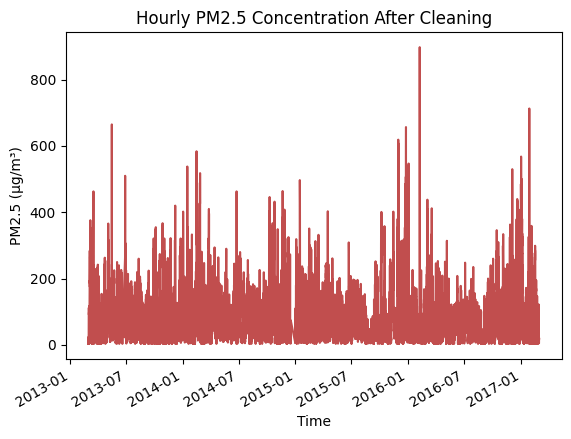

In [17]:
import matplotlib.pyplot as plt

df_clean["PM2.5"].plot(color="firebrick", alpha=0.8)
plt.title("Hourly PM2.5 Concentration After Cleaning")
plt.ylabel("PM2.5 (µg/m³)")
plt.xlabel("Time")
plt.show()

/tmp/ipykernel_3225/886585877.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_pm25 = df_clean["PM2.5"].resample("M").mean()


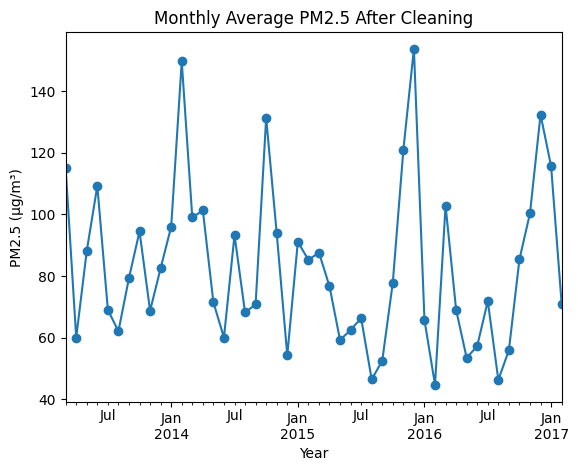

In [18]:
monthly_pm25 = df_clean["PM2.5"].resample("M").mean()

monthly_pm25.plot(marker="o")
plt.title("Monthly Average PM2.5 After Cleaning")
plt.ylabel("PM2.5 (µg/m³)")
plt.xlabel("Year")
plt.show()

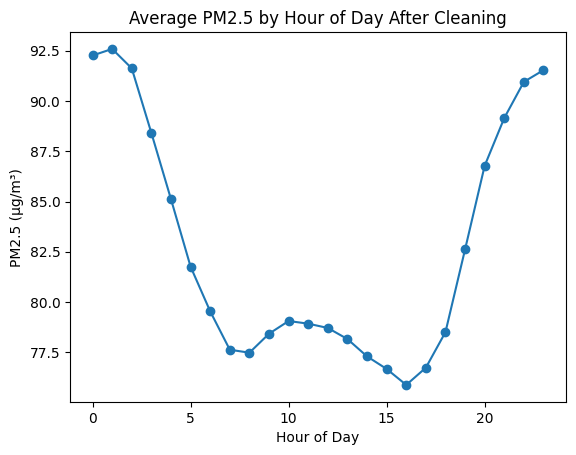

In [19]:
hourly_pattern = df_clean.groupby(df_clean.index.hour)["PM2.5"].mean()

hourly_pattern.plot(marker="o")
plt.title("Average PM2.5 by Hour of Day After Cleaning")
plt.xlabel("Hour of Day")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

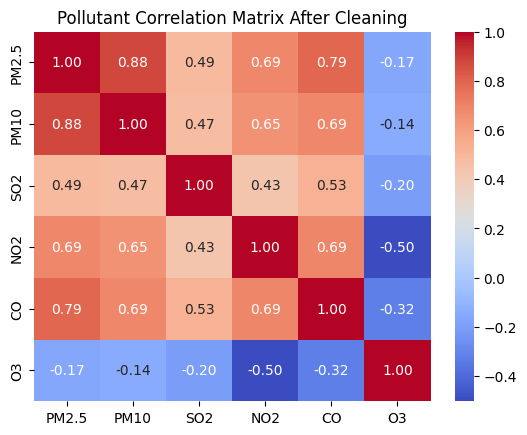

In [20]:
import seaborn as sns

pollutants = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
corr = df_clean[pollutants].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Pollutant Correlation Matrix After Cleaning")
plt.show()